# Chemical and elastic spinodal decomposition

I evolve a conserved dimensionless composition c on a periodic grid. The bulk energy is c²(1−c)². The chemical potential contains its derivative, a gradient contribution and, in elastic mode, a homogeneous elastic contribution. n is the number of points per direction, dt is the time step, and steps is the number of updates. All model quantities are dimensionless.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## 1. Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## 2. Choose the input values

I retain the default values from the original calculation. The output name locates the files written by this notebook.

In [2]:
mode = 'chemical'
output = 'phase-field-results'
n = None
dt = 0.2
steps = 2000

## 3. Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [3]:
import sys
from pathlib import Path
import numpy as np

## 4. Calculate the elastic kernel

I calculate B for each wave-vector direction from the stiffness constants and a dilatational misfit. C11, C12 and C44 are the stiffness constants, and eigenstrain is the prescribed stress-free strain. This example uses dimensionless stiffness and strain. The zero mode corresponds to the specified macroscopic condition; it is not a directional mode.

In [4]:
def kernel(kx, ky, c11=4.0, c12=2.0, c44=3.0, eigenstrain=0.2):
    """B = E:C:E - (sigma0.n).Q^-1.(sigma0.n), E=eigenstrain*I.
    Q_ik=C_ijkl*n_j*n_l; Q11=C11*nx²+C44*ny² (not C12).
    This is a 2D constitutive model, not a reduction with epsilon_zz eigenstrain.
    """
    k2 = kx * kx + ky * ky
    radius = np.sqrt(np.where(k2 == 0, 1.0, k2))
    nx, ny = (kx / radius, ky / radius)
    q11 = c11 * nx * nx + c44 * ny * ny
    q22 = c44 * nx * nx + c11 * ny * ny
    q12 = (c12 + c44) * nx * ny
    det = q11 * q22 - q12 * q12
    det = np.where(k2 == 0, 1.0, det)
    stress = (c11 + c12) * eigenstrain
    b = 2 * (c11 + c12) * eigenstrain ** 2 - stress ** 2 * (q22 * nx * nx - 2 * q12 * nx * ny + q11 * ny * ny) / det
    return np.where(k2 == 0, 0.0, b)

## 5. Set up the Fourier grid

I calculate wave numbers consistent with the grid spacing and periodic domain. k2 denotes the squared magnitude of a wave vector. The denominator contains the term treated implicitly in the original update. The zero Fourier mode represents the spatial mean.

In [5]:
out = Path(output)
out.mkdir(parents=True, exist_ok=True)
if n is None:
    n = 256 if mode == 'elastic' else 64
if mode not in ('chemical', 'elastic'):
    raise ValueError('Choose chemical or elastic')
k = 2 * np.pi * np.fft.fftfreq(n)
kx, ky = np.meshgrid(k, k, indexing='ij')
k2 = kx * kx + ky * ky
b = kernel(kx, ky) if mode == 'elastic' else np.zeros_like(k2)
partner = -np.arange(n) % n

## 6. Set up the Fourier grid

I calculate wave numbers consistent with the grid spacing and periodic domain. k2 denotes the squared magnitude of a wave vector. The denominator contains the term treated implicitly in the original update. The zero Fourier mode represents the spatial mean.

In [6]:
b = 0.5 * (b + b[np.ix_(partner, partner)])
i, j = np.meshgrid(np.arange(n), np.arange(n), indexing='ij')
noise = np.sin((i + 1) * 12.9898 + (j + 1) * 78.233) * 43758.5453
noise = 0.02 * (noise - np.floor(noise) - 0.5)
noise -= noise.mean()
c = 0.5 + noise
initial_mean = c.mean()
records = []
denominator = 1 + dt * k2 * (k2 + b)

## 7. Define record

I define this operation before calling it. I keep its arguments explicit so I can test it separately.

In [7]:
def record(step):
    h = np.fft.fft2(c)
    energy = np.mean(c * c * (1 - c) ** 2) + 0.5 * np.sum((k2 + b) * np.abs(h) ** 2) / n ** 4
    records.append([step * dt, c.mean(), energy, c.min(), c.max()])
    np.savetxt(out / f'field_{step:04d}.csv', c, delimiter=',')

## 8. Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [8]:
record(0)

## 9. Advance the field and record the result

I apply the update in its original order. I record the mean, energy or other diagnostics at the specified intervals. I do not clip the numerical field. A saved picture is a display of the field, not a substitute for a conservation check.

In [9]:
for step in range(1, steps + 1):
    h = (np.fft.fft2(c) - dt * k2 * np.fft.fft2(2 * c * (1 - c) * (1 - 2 * c))) / denominator
    c = np.fft.ifft2(h).real
    if step % 25 == 0 or step == steps:
        record(step)

## 10. Check the result before continuing

I check finite values, conservation or the known reference result as specified below. An assertion stops the notebook if the condition fails. Inspect the quantities and tolerance rather than suppressing a failure.

In [10]:
assert np.isfinite(c).all()
assert abs(c.mean() - initial_mean) < 1e-10
np.savetxt(out / 'diagnostics.csv', records, delimiter=',', header='time,mean,energy_density,min,max', comments='')
print(mode, 'mean drift', abs(c.mean() - initial_mean), 'energy', records[0][2], records[-1][2])

chemical mean drift 5.551115123125783e-15 energy 0.06259237590968526 0.02567399956688033


## Plot and interpret the result

I plot c without changing its stored values. The color scale is a display choice. The mean checks test conservation, while the sampled energy history helps assess this particular run. It does not prove stability for arbitrary time steps.

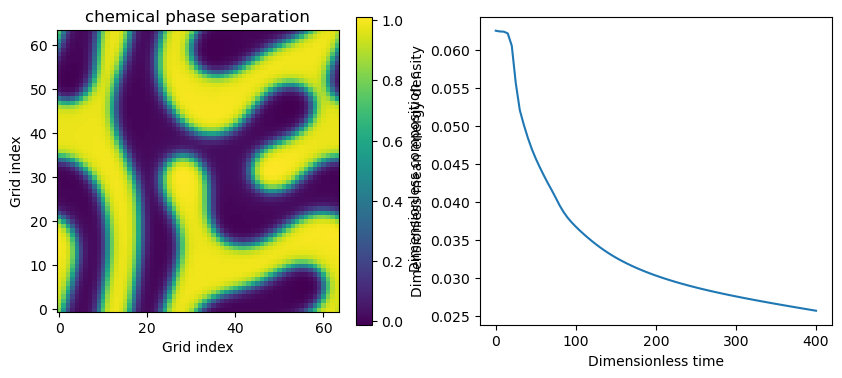

In [11]:
import matplotlib.pyplot as plt
values = np.asarray(records)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
image = axes[0].imshow(c, origin="lower")
fig.colorbar(image, ax=axes[0], label="Dimensionless composition c")
axes[0].set_title(mode + " phase separation")
axes[0].set_xlabel("Grid index")
axes[0].set_ylabel("Grid index")
axes[1].plot(values[:, 0], values[:, 2])
axes[1].set_xlabel("Dimensionless time")
axes[1].set_ylabel("Dimensionless mean energy density")
plt.show()

## 11. Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/examples/phase_field.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.